# 01. Случайный лес

**Идея.** Одно дерево решений — набор вопросов вида «в последней реплике больше 40 символов?». Оно легко переобучается.
Случайный лес строит много деревьев, каждое на случайной части диалогов и случайных признаков, а ответ получается
голосованием деревьев. Ошибки отдельных деревьев усредняются.

Порядок: (1) модель по умолчанию как точка отсчёта, (2) случайный поиск параметров на кросс-валидации, (3) выбор числа деревьев,
(4) итог и сохранение, (5) важность признаков, (6) test — один раз в самом конце.

Данные, разбиение и блоки CV — те же, что у старых моделей (первая ячейка).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

import solution_utils as su
from solution_utils import CLASSES, SEED

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

# 1. Чтение даннных и разбиение (пока точь-в-точь как в solution.ipynb)

In [2]:
# Задача 1 из HW1: диалоги с use_reaction == 1 (флаги из dialog_flags.csv), разбиение по group_id
task1 = su.load_task1(su.train_path(), su.flags_path())
train_df, test_df = su.split_task1(task1)          # то же train/test, что в HW1

train_dialogs = train_df[["dialog_id", "turns"]].to_dict("records")
test_dialogs = test_df[["dialog_id", "turns"]].to_dict("records")
y_train, y_test = train_df["reaction"].to_numpy(), test_df["reaction"].to_numpy()
folds = su.get_folds(y_train, train_df["group_id"].to_numpy())   # одни блоки CV для всех моделей

print(f"всего для задачи 1: {len(task1)} | train: {len(train_df)} | test: {len(test_df)}")
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True),
              "test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES].round(3)

всего для задачи 1: 2930 | train: 2344 | test: 586


,train,test
negative,0.308,0.305
neutral,0.593,0.606
positive,0.098,0.089


## Признаки для дерева

`make_frame` превращает диалог в таблицу: тексты пользователя (все реплики и последняя) и числа. Создается, опираясь на файл с флагами после EDA из первой домашки

In [18]:
dialog_flags = su.load_flags()

su.make_frame(train_dialogs[:3], dialog_flags).to_csv(
    "artifacts/results/rf_features_example.csv", 
    index=False,  # не сохранять служебный индекс строки
    encoding="utf-8"
)

## Модель: `Pipeline`

Создали .

- `TfidfVectorizer` — текст трансформируем в числа по частоте слов (отдельно для всех реплик и для последней);
- `"passthrough"` — числовые колонки идут как есть;
- `class_weight="balanced"` — редкие классы (positive всего ~10%) получают больший вес.

In [4]:
def build_pipeline(n_estimators=300):
    features = ColumnTransformer([
        ("all_tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=3000), "user_text"),
        ("last_tfidf", TfidfVectorizer(min_df=3, max_features=1000), "last_user"),
        ("numeric", "passthrough", su.NUMERIC_COLUMNS),
    ])
    forest = RandomForestClassifier(n_estimators=n_estimators, class_weight="balanced", n_jobs=-1, random_state=SEED)
    return Pipeline([("features", features), ("rf", forest)])  


X_train = su.make_frame(train_dialogs, dialog_flags)
X_test = su.make_frame(test_dialogs, dialog_flags)

# 2. Сравним для понимания лучшую из старых моделей и лес с параметарми по умолчанию

Кросс-валидируем наш лес

In [5]:
history = [{"шаг": "по умолчанию", **su.cv_metrics(build_pipeline(), X_train, y_train, folds, n_jobs=1)}]
pd.DataFrame(history).round(3)[["шаг", "macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro"]]

,шаг,macro_f1,accuracy,balanced_accuracy,roc_auc_macro
0,по умолчанию,0.604,0.694,0.577,0.779


Вспомним лучшую из худших (старых моеделек из первой домашки)

In [7]:
old_cv = pd.read_csv("artifacts/results/cv_table.csv", index_col=0)
old_cv = old_cv[old_cv.index.str.startswith("hw1_")]
print("лучшая старая модель на CV:", old_cv["macro_f1"].idxmax(), round(old_cv["macro_f1"].max(), 3))

лучшая старая модель на CV: hw1_tfidf_logreg 0.583


# 3. Подбор параметров (`RandomizedSearchCV`)

Перебирать все комбинации долго, взяли 40 случайных. Для каждой — те же 5 блоков `folds`, оценивали  по `f1_macro`.

| параметр | смысл |
|:--|:--|
| `max_depth` | максимальная глубина дерева; меньше — проще дерево и меньше переобучение |
| `min_samples_leaf` | устанавливаем минимум диалогов в листе; больше — устойчивее |
| `max_features` | сколько признаков смотрит дерево в каждом разбиении; меньше — деревья разнообразнее |
| `class_weight` | способ балансировки классов (решили еще с бустраппом попоробовать)|
| `max_samples` | какую долю диалогов видит каждое дерево по отдельности|
| `max_features` у TF-IDF | сколько слов оставить |

Имя вида `шаг__параметр` — так `Pipeline` понимает, к какому шагу относится параметр.

In [21]:
param_distributions = {
    "rf__max_depth": [10, 20, 40, 50],
    "rf__min_samples_leaf": [1, 2, 3, 5],
    "rf__max_features": ["sqrt", "log2", 0.1],
    "rf__class_weight": ["balanced", "balanced_subsample"],
    "rf__max_samples": [0.1, 0.3, 0.6],
    "features__all_tfidf__max_features": [1000, 3000, 5000],
}

search = RandomizedSearchCV(build_pipeline(), param_distributions, n_iter=50, scoring="f1_macro",
                            cv=folds, random_state=SEED, n_jobs=1, refit=True, verbose=1)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score"] + [c for c in results.columns if c.startswith("param_")]

results[cols].to_csv("artifacts/results/rf_search_run1_top20.csv", index=False)       # путь подбора для отчёта

print("лучший macro-F1 на CV:", round(search.best_score_, 3))
print(search.best_params_)
results[cols].head(20).round(3)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
лучший macro-F1 на CV: 0.606
{'rf__min_samples_leaf': 3, 'rf__max_samples': 0.6, 'rf__max_features': 0.1, 'rf__max_depth': 40, 'rf__class_weight': 'balanced_subsample', 'features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
28,0.606,0.028,3,0.6,0.1,40,balanced_subsample,1000
10,0.605,0.041,2,0.6,0.1,40,balanced,3000
18,0.600,0.043,1,0.6,0.1,50,balanced,5000
14,0.598,0.044,3,0.6,0.1,40,balanced,5000
49,0.598,0.031,1,0.6,sqrt,20,balanced,3000
22,0.594,0.030,1,0.6,0.1,20,balanced_subsample,3000
13,0.590,0.037,1,0.6,0.1,10,balanced_subsample,3000
45,0.589,0.030,3,0.3,0.1,20,balanced_subsample,1000
26,0.589,0.048,2,0.3,0.1,50,balanced,1000
35,0.583,0.046,1,0.3,0.1,50,balanced,1000


Пробую еще один прогон, подкорректировав параметры, которые дают повод задуматься об улучшении модели

In [23]:
param_distributions = {
    "rf__max_depth": [10, 20, 40, 50],
    "rf__min_samples_leaf": [2, 6, 7, 8, 10],
    "rf__max_features": ["sqrt", "log2", 0.1],
    "rf__class_weight": ["balanced", "balanced_subsample"],
    "rf__max_samples": [0.7, 0.8, 0.9],
    "features__all_tfidf__max_features": [1000, 3000],
}

search = RandomizedSearchCV(build_pipeline(), param_distributions, n_iter=40, scoring="f1_macro",
                            cv=folds, random_state=SEED, n_jobs=1, refit=True, verbose=1)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score"] + [c for c in results.columns if c.startswith("param_")]

Fitting 5 folds for each of 40 candidates, totalling 200 fits


In [24]:
results[cols].to_csv("artifacts/results/rf_search.csv", index=False)       # путь подбора для отчёта

print("лучший macro-F1 на CV:", round(search.best_score_, 3))
print(search.best_params_)
results[cols].head(20).round(3)

лучший macro-F1 на CV: 0.614
{'rf__min_samples_leaf': 2, 'rf__max_samples': 0.7, 'rf__max_features': 0.1, 'rf__max_depth': 40, 'rf__class_weight': 'balanced', 'features__all_tfidf__max_features': 1000}


,mean_test_score,std_test_score,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__max_features,param_rf__max_depth,param_rf__class_weight,param_features__all_tfidf__max_features
28,0.614,0.046,2,0.7,0.1,40,balanced,1000
36,0.612,0.034,6,0.9,0.1,50,balanced_subsample,3000
17,0.604,0.034,7,0.9,0.1,20,balanced_subsample,3000
10,0.604,0.028,6,0.7,0.1,50,balanced_subsample,3000
27,0.603,0.034,2,0.7,0.1,10,balanced_subsample,1000
16,0.600,0.040,6,0.9,0.1,20,balanced,1000
20,0.599,0.042,6,0.9,0.1,20,balanced,3000
38,0.599,0.043,8,0.9,0.1,10,balanced_subsample,3000
7,0.598,0.032,2,0.9,sqrt,50,balanced,1000
34,0.598,0.035,6,0.7,0.1,10,balanced_subsample,3000



`Что имеем:`

Несмотря на то, что лучшая модель показала macro_f1 = 0.614, в процессе подбора гиперпараметров были конфигурации с результатом ниже базового (самое низкое = 0.564).

Ограничение глубины и размера листа (недообучение). Комбинации с max_depth = 40 или 20 и min_samples_leaf=5 не позволяют деревьям выстраивать достаточно длинные логические цепочки для классификации сложных текстов. Деревья останавливаются раньше времени.

Использование max_features="sqrt" или "log2". На данном датасете эти значения дают деревьям слишком мало признаков для анализа, из-за чего они не находят информативные текстовые паттерны. Оптимальным оказалось значение 0.1. Получается, деревья по отдельности берут мало признаков, но это делает их разнообразными, а значит менее "заинтересованными" в конечном предсказании, что хорошо для задачи (что согласуется с теорией).



### Проверим еще, какое количество деревьев нам подойдет лучше

Деревьев больше — результат стабильнее, но дольше.
Возьмем **наименьшее** число, после которого прироста macro-F1 почти нет.

In [25]:
sizes = [50, 100, 200, 300, 400, 500, 600, 700, 800]
scores = []
for n in sizes:
    model = clone(build_pipeline(n)).set_params(**search.best_params_)
    scores.append(cross_val_score(model, X_train, y_train, cv=folds, scoring="f1_macro", n_jobs=1).mean())


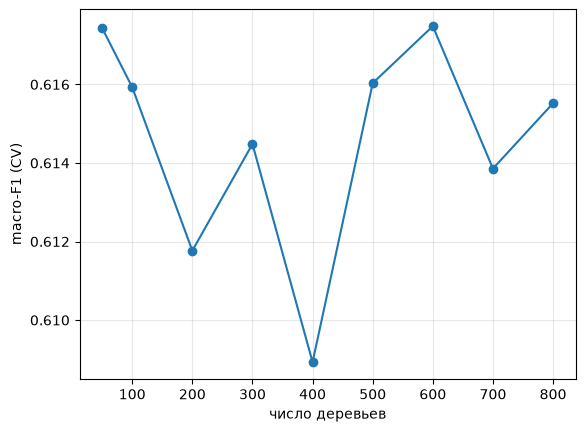

In [26]:
plt.plot(sizes, scores, marker="o")
plt.xlabel("число деревьев"); plt.ylabel("macro-F1 (CV)"); plt.grid(alpha=0.3)
plt.savefig("artifacts/results/rf_n_estimators.png", dpi=120, bbox_inches="tight")
plt.show()

In [27]:
N_TREES = 500
print(f"Лучшее число деревьев: {N_TREES}")

Лучшее число деревьев: 500


# 4. Итоговая модель

СV лучшей модели, записываем метрики в общую таблицу. Обучаем на всём train и сохраняем `artifacts/hw2_random_forest.joblib`.


In [28]:
final = clone(build_pipeline(N_TREES)).set_params(**search.best_params_)
final_row = su.cv_metrics(final, X_train, y_train, folds, n_jobs=1)
history.append({"шаг": "лучшая м", **final_row})
pd.DataFrame(history).round(3).to_csv("artifacts/results/rf_history.csv", index=False)


In [29]:
cv_table = su.save_result("cv_table.csv", "hw2_random_forest", final_row)
final.fit(X_train, y_train)
print("сохранено:", su.save_model("hw2_random_forest", final))
cv_table.round(3)     # общая таблица: старые модели и случайный лес

сохранено: /home/pavel-ubunt/Рабочий стол/ML_mipt/MIPT_ML_homework/solution_hw_2_BKZ/artifacts/hw2_random_forest.joblib


,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.618,0.684,0.609,0.781,0.640,0.597,0.573,0.747,0.776,0.539,0.478
hw1_tfidf_logreg,0.583,0.704,0.560,0.783,0.621,0.637,0.607,0.740,0.830,0.596,0.243
hw1_kirp_model,0.564,0.701,0.542,0.777,0.609,0.637,0.588,0.731,0.843,0.616,0.196
hw1_bow_logreg,0.529,0.656,0.516,0.703,0.514,0.585,0.505,0.710,0.803,0.374,0.239
hw1_stratified,0.348,0.467,0.349,0.513,0.339,0.329,0.357,0.607,0.584,0.109,0.104
hw1_most_frequent,0.248,0.593,0.333,0.500,0.333,0.000,0.000,0.593,1.000,0.000,0.000


In [30]:
best_old = cv_table[cv_table.index.str.startswith("hw1_")]["macro_f1"].max()
gain = final_row["macro_f1"] - best_old
print(f"лес: {final_row['macro_f1']:.3f} | лучшая старая: {best_old:.3f} | разница: {gain:+.3f}")

лес: 0.618 | лучшая старая: 0.583 | разница: +0.034


## Шаг 5. Важность признаков (MDI)

MDI показывает, насколько признак в среднем уменьшал неоднородность узлов по всем деревьям. Считается быстро, но склонна
завышать важность числовых признаков с большим разбросом значений. Перестановочную важность (`sklearn.inspection.permutation_importance`)
для сравнения сделает тот, кто пишет этот раздел отчёта.

In [36]:
names = final.named_steps["features"].get_feature_names_out()
importance = pd.Series(final.named_steps["rf"].feature_importances_, index=names)
importance.to_csv("artifacts/results/rf_mdi_top15.csv", index = True)

importance.sort_values(ascending=False).head(15).round(4)

all_tfidf__thanks              0.0384
all_tfidf__thank               0.0270
all_tfidf__thank you           0.0267
all_tfidf__you                 0.0234
numeric__has_assistant_code    0.0201
numeric__has_code              0.0145
all_tfidf__what                0.0129
numeric__nn_sim                0.0120
numeric__n_chars_total         0.0120
last_tfidf__thanks             0.0109
last_tfidf__you                0.0099
numeric__max_msg_chars         0.0095
all_tfidf__of                  0.0089
all_tfidf__and                 0.0088
all_tfidf__no                  0.0087
dtype: float64

permutation_importance пока считать не стал - 2020 признаков считаются оверхдохрена времени

## Шаг 6. Test — запускать один раз

Test нельзя использовать для выбора параметров. Эту ячейку запускаем **один раз**, когда модель окончательно готова.

In [32]:
proba_test = final.predict_proba(X_test)
test_table = su.save_result("test_table.csv", "hw2_random_forest", su.all_metrics(y_test, proba_test))
test_pred = final.classes_[proba_test.argmax(axis=1)]
display(test_table.round(3))

cm_df = pd.DataFrame(confusion_matrix(y_test, test_pred, labels=CLASSES),
             index=[f"факт {c}" for c in CLASSES], columns=[f"предсказано {c}" for c in CLASSES])
cm_df.to_csv("artifacts/results/rf_confusion_matrix.csv", index=True)
cm_df

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
hw2_random_forest,0.637,0.712,0.622,0.795,0.640,0.635,0.564,0.758,0.820,0.581,0.481
hw1_tfidf_logreg,0.593,0.727,0.559,0.776,0.642,0.692,0.564,0.738,0.882,0.750,0.231
hw1_kirp_model,0.581,0.724,0.547,0.781,0.639,0.685,0.570,0.731,0.879,1.000,0.192
hw1_bow_logreg,0.494,0.654,0.484,0.676,0.493,0.608,0.486,0.702,0.811,0.242,0.154
hw1_stratified,0.324,0.452,0.324,0.493,0.331,0.277,0.291,0.606,0.586,0.091,0.096
hw1_most_frequent,0.252,0.606,0.333,0.500,0.333,0.000,0.000,0.606,1.000,0.000,0.000


,предсказано negative,предсказано neutral,предсказано positive
факт negative,101,73,5
факт neutral,51,291,13
факт positive,7,20,25
